## 1. Import Libraries
This cell imports the Python libraries and machine-learning tools used throughout the notebook. It includes pandas for data manipulation, pathlib for file paths, Matplotlib for visualization, and scikit-learn components for preprocessing, regression models, and evaluation metrics.

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor,HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.dummy import DummyRegressor

import joblib
import os

## 2. Inspect the Available Data Files
This cell searches the project data directory for CSV and Parquet files. For each file, it displays its dimensions, column names, data types, sample rows, missing values, duplicate rows, and memory usage. This provides an initial overview of the available datasets and their quality.

In [2]:
DATA_PATH = Path(r"D:\next Gen In Ai\Final Project\Data")

files = list(DATA_PATH.glob("*.csv")) + list(DATA_PATH.glob("*.parquet"))

for file in files:

    print("\n" + "=" * 65)
    print(f"FILE: {file.name}")
    print("=" * 65)

    if file.suffix == ".csv":
        df = pd.read_csv(file)
    else:
        df = pd.read_parquet(file)

    print("Shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nFirst 5 Rows:")
    print(df.head())

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())

    print("\nMemory Usage:")
    print(round(df.memory_usage(deep=True).sum() / 1024**2, 2), "MB")



FILE: AEP_hourly.csv
Shape: (121273, 2)

Columns:
['Datetime', 'AEP_MW']

Data Types:
Datetime        str
AEP_MW      float64
dtype: object

First 5 Rows:
              Datetime   AEP_MW
0  2004-12-31 01:00:00  13478.0
1  2004-12-31 02:00:00  12865.0
2  2004-12-31 03:00:00  12577.0
3  2004-12-31 04:00:00  12517.0
4  2004-12-31 05:00:00  12670.0

Missing Values:
Datetime    0
AEP_MW      0
dtype: int64

Duplicate Rows:
0

Memory Usage:
4.05 MB

FILE: COMED_hourly.csv
Shape: (66497, 2)

Columns:
['Datetime', 'COMED_MW']

Data Types:
Datetime        str
COMED_MW    float64
dtype: object

First 5 Rows:
              Datetime  COMED_MW
0  2011-12-31 01:00:00    9970.0
1  2011-12-31 02:00:00    9428.0
2  2011-12-31 03:00:00    9059.0
3  2011-12-31 04:00:00    8817.0
4  2011-12-31 05:00:00    8743.0

Missing Values:
Datetime    0
COMED_MW    0
dtype: int64

Duplicate Rows:
0

Memory Usage:
2.22 MB

FILE: DAYTON_hourly.csv
Shape: (121275, 2)

Columns:
['Datetime', 'DAYTON_MW']

Data Types:
Da

## 3. Standardize and Combine Regional Datasets
This cell reads the regional CSV files, identifies their date and numeric consumption columns, and standardizes the column names. It adds a region identifier based on each filename, combines the datasets into one table, converts timestamps, and sorts the records for further analysis.

In [3]:
data_path = Path(r"D:\next Gen In Ai\Final Project\Data")

all_data = []

for file in data_path.glob("*.csv"):

    df = pd.read_csv(file)

    # Identify the datetime column
    date_col = next(
        (col for col in df.columns
         if col.lower() in ["datetime", "date", "timestamp"]),
        None
    )

    if date_col is None:
        print(f"Missing datetime column: {file.name}")
        continue

    # Identify consumption column
    value_cols = [
        col for col in df.select_dtypes(include="number").columns
        if col != date_col
    ]

    if len(value_cols) != 1:
        print(f"Check columns manually: {file.name}")
        continue

    df = df[[date_col, value_cols[0]]].copy()

    # Standardize column names
    df.columns = ["Datetime", "Consumption"]

    # Add region name
    df["Region"] = file.stem.replace("_hourly", "")

    all_data.append(df)

# Combine all datasets
final_df = pd.concat(all_data, ignore_index=True)

# Convert datetime
final_df["Datetime"] = pd.to_datetime(final_df["Datetime"])

# Sort data
final_df = final_df.sort_values(
    ["Region", "Datetime"]
).reset_index(drop=True)

print(final_df.head())
print(final_df.shape)


Check columns manually: pjm_hourly_est.csv
             Datetime  Consumption Region
0 2004-10-01 01:00:00      12379.0    AEP
1 2004-10-01 02:00:00      11935.0    AEP
2 2004-10-01 03:00:00      11692.0    AEP
3 2004-10-01 04:00:00      11597.0    AEP
4 2004-10-01 05:00:00      11681.0    AEP
(1090167, 3)


## 4. Load the PJM Hourly Dataset
This cell loads the main PJM hourly electricity dataset into a DataFrame and calculates the number of missing values in each column. It provides the starting point for the detailed inspection of the regional time series.

In [4]:
# PJM_hourly
PJM_hourly = pd.read_csv(r"D:\next Gen In Ai\Final Project\Data\pjm_hourly_est.csv")
PJM_hourly.isnull().sum()
# print("PJM_hourly shape:",PJM_hourly.shape)

Datetime         0
AEP          56989
COMED       111765
DAYTON       56987
DEOK        120523
DOM          62073
DUQ          59194
EKPC        132928
FE          115388
NI          119812
PJME         32896
PJMW         35056
PJM_Load    145366
dtype: int64

## 5. Explore the Dataset Structure and Quality
This cell examines the dataset dimensions and data types, calculates missing-value counts and percentages, converts the timestamp column to datetime, and checks the date range and duplicate timestamps. It also displays the first and last records to inspect the data boundaries.

In [5]:
# 
# 1. Dataset Information

print("Dataset Shape:", PJM_hourly.shape)

print("\nData Types:")
print(PJM_hourly.dtypes)

# 2. Missing Values Percentage

missing = pd.DataFrame({
    "Missing_Count": PJM_hourly.isnull().sum(),
    "Missing_Percentage": (
        PJM_hourly.isnull().mean() * 100
    ).round(2)
})

print("\nMissing Values Analysis:")
print(missing.sort_values(
    "Missing_Percentage",
    ascending=False
))

# 3. Datetime Analysis

PJM_hourly["Datetime"] = pd.to_datetime(
    PJM_hourly["Datetime"]
)

print("\nDate Range:")
print("Start:", PJM_hourly["Datetime"].min())
print("End:", PJM_hourly["Datetime"].max())

# 4. Duplicate Datetimes

print(
    "\nDuplicate Datetimes:",
    PJM_hourly["Datetime"].duplicated().sum()
)

# 5. First 5 Rows

print("\nFirst 5 Rows:")
print(PJM_hourly.head())

# 6. Last 5 Rows

print("\nLast 5 Rows:")
print(PJM_hourly.tail())


Dataset Shape: (178262, 13)

Data Types:
Datetime        str
AEP         float64
COMED       float64
DAYTON      float64
DEOK        float64
DOM         float64
DUQ         float64
EKPC        float64
FE          float64
NI          float64
PJME        float64
PJMW        float64
PJM_Load    float64
dtype: object

Missing Values Analysis:
          Missing_Count  Missing_Percentage
PJM_Load         145366               81.55
EKPC             132928               74.57
DEOK             120523               67.61
NI               119812               67.21
FE               115388               64.73
COMED            111765               62.70
DOM               62073               34.82
DUQ               59194               33.21
AEP               56989               31.97
DAYTON            56987               31.97
PJMW              35056               19.67
PJME              32896               18.45
Datetime              0                0.00

Date Range:
Start: 1998-04-01 01:00:00
End

## 6. Analyze Data Coverage by Region
This cell creates a separate coverage summary for each region. It measures the number of available readings, the first and last valid timestamps, the percentage of missing values, and the number of gaps longer than one hour. It also checks invalid and duplicated timestamps.

In [6]:
df = PJM_hourly.copy()

# Convert Datetime
df["Datetime"] = pd.to_datetime(
    df["Datetime"],
    errors="coerce"
)

regions = df.columns.drop("Datetime")

# Analyze each region
coverage = []

for region in regions:

    valid_data = df.loc[
        df[region].notna(),
        ["Datetime", region]
    ].dropna(subset=["Datetime"])

    valid_data = valid_data.sort_values("Datetime")

    time_diff = valid_data["Datetime"].diff()

    coverage.append({
        "Region": region,
        "Available_Rows": len(valid_data),
        "Start_Date": valid_data["Datetime"].min(),
        "End_Date": valid_data["Datetime"].max(),
        "Missing_Percentage": round(
            df[region].isna().mean() * 100, 2
        ),
        "Gaps_Over_1_Hour": (
            time_diff > pd.Timedelta(hours=1)
        ).sum()
    })

coverage_df = pd.DataFrame(coverage)

print(coverage_df.to_string(index=False))

# Check duplicate timestamps
print(
    "\nDuplicate Datetimes:",
    df["Datetime"].duplicated().sum()
)

# Check invalid dates
print(
    "Invalid Datetimes:",
    df["Datetime"].isna().sum()
)


  Region  Available_Rows          Start_Date   End_Date  Missing_Percentage  Gaps_Over_1_Hour
     AEP          121273 2004-10-01 01:00:00 2018-08-03               31.97                27
   COMED           66497 2011-01-01 01:00:00 2018-08-03               62.70                11
  DAYTON          121275 2004-10-01 01:00:00 2018-08-03               31.97                25
    DEOK           57739 2012-01-01 01:00:00 2018-08-03               67.61                 9
     DOM          116189 2005-05-01 01:00:00 2018-08-03               34.82                23
     DUQ          119068 2005-01-01 01:00:00 2018-08-03               33.21                24
    EKPC           45334 2013-06-01 01:00:00 2018-08-03               74.57                 6
      FE           62874 2011-06-01 01:00:00 2018-08-03               64.73                10
      NI           58450 2004-05-01 01:00:00 2011-01-01               67.21                14
    PJME          145366 2002-01-01 01:00:00 2018-08-03     

## 7. Investigate Duplicate Timestamps and Time Gaps
This cell examines records with repeated timestamps, checks for exact duplicate rows, and identifies whether repeated timestamps contain conflicting regional values. It also calculates missing hourly intervals between consecutive valid readings for each region.

In [7]:

# =====================================
# 1. Inspect Duplicate Datetimes
# =====================================

duplicates = df[
    df["Datetime"].duplicated(keep=False)
].sort_values("Datetime")

print("Duplicate Records:")
print(duplicates.to_string(index=False))

print("\nExact Duplicate Rows:")
print(df.duplicated().sum())

print("\nNumber of Duplicate Timestamps:")
print(df["Datetime"].duplicated().sum())


# =====================================
# 2. Check Conflicting Values
# =====================================

regions = df.columns.drop("Datetime")

conflicts = {}

for region in regions:

    duplicated_values = (
        df.groupby("Datetime")[region]
        .nunique()
    )

    conflicts[region] = (
        duplicated_values > 1
    ).sum()

print("\nConflicting Values Per Region:")
print(pd.Series(conflicts))


# =====================================
# 3. Calculate Missing Hourly Intervals
# =====================================

gap_results = []

for region in regions:

    timestamps = (
        df.loc[df[region].notna(), "Datetime"]
        .dropna()
        .drop_duplicates()
        .sort_values()
    )

    differences = timestamps.diff()

    missing_hours = (
        differences.dt.total_seconds() / 3600 - 1
    ).clip(lower=0).sum()

    gap_results.append({
        "Region": region,
        "Missing_Hours_Between_Readings": int(
            missing_hours
        ),
        "Number_Of_Gaps": int(
            (differences > pd.Timedelta(hours=1)).sum()
        )
    })

gap_df = pd.DataFrame(gap_results)

print("\nTime Gaps Analysis:")
print(gap_df.to_string(index=False))


Duplicate Records:
           Datetime     AEP  COMED  DAYTON   DEOK    DOM    DUQ   EKPC     FE  NI    PJME   PJMW  PJM_Load
2014-11-02 02:00:00 12994.0 8869.0  1623.0 2518.0 8555.0 1272.0 1554.0 6051.0 NaN 22935.0 4613.0       NaN
2014-11-02 02:00:00 13190.0 9184.0  1634.0 2562.0 8562.0 1240.0 1566.0 6185.0 NaN 23755.0 4571.0       NaN
2015-11-01 02:00:00 10785.0 8270.0  1324.0 2164.0 7392.0 1113.0  978.0 5653.0 NaN 21567.0 3927.0       NaN
2015-11-01 02:00:00 10542.0 7923.0  1292.0 2257.0 7345.0 1138.0  944.0 5455.0 NaN 21171.0 3832.0       NaN
2016-11-06 02:00:00 10964.0 7814.0  1334.0 2350.0 7924.0 1121.0 1042.0 5523.0 NaN 20795.0 4114.0       NaN
2016-11-06 02:00:00 11008.0 8028.0  1364.0 2198.0 8145.0 1107.0 1028.0 5587.0 NaN 21692.0 4089.0       NaN
2017-11-05 02:00:00 10596.0 8198.0  1449.0 2064.0 7677.0 1131.0  910.0 5573.0 NaN 21236.0 4042.0       NaN
2017-11-05 02:00:00 10446.0 7878.0  1331.0 1044.0 7468.0 1105.0  900.0 5467.0 NaN 20666.0 3984.0       NaN

Exact Duplicate R

## 8. Inspect Records Around Duplicate Timestamps
This cell finds all duplicated timestamps and prints the nearby rows for each occurrence. Showing the surrounding records helps determine whether duplicates are isolated, part of a repeated sequence, or associated with other data-quality issues.

In [8]:

# Get duplicated timestamps
duplicate_times = (
    df.loc[
        df["Datetime"].duplicated(keep=False),
        "Datetime"
    ]
    .drop_duplicates()
)

# Display surrounding records
for timestamp in duplicate_times:

    print("\n", "=" * 60)
    print("Duplicate Timestamp:", timestamp)

    positions = [
        i for i, value in enumerate(df["Datetime"])
        if value == timestamp
    ]

    for pos in positions:

        print(f"\nPosition: {pos}")

        print(
            df.iloc[
                max(0, pos - 2):pos + 3
            ].to_string(index=False)
        )



Duplicate Timestamp: 2014-11-02 02:00:00

Position: 139480
           Datetime     AEP   COMED  DAYTON   DEOK    DOM    DUQ   EKPC     FE  NI    PJME   PJMW  PJM_Load
2014-11-04 00:00:00 13448.0 10018.0  1741.0 2469.0 8696.0 1357.0 1282.0 6606.0 NaN 25583.0 5005.0       NaN
2014-11-02 01:00:00 13297.0  9573.0  1682.0 2623.0 8839.0 1222.0 1589.0 6012.0 NaN 23538.0 4805.0       NaN
2014-11-02 02:00:00 12994.0  8869.0  1623.0 2518.0 8555.0 1272.0 1554.0 6051.0 NaN 22935.0 4613.0       NaN
2014-11-02 02:00:00 13190.0  9184.0  1634.0 2562.0 8562.0 1240.0 1566.0 6185.0 NaN 23755.0 4571.0       NaN
2014-11-02 03:00:00 12835.0  8788.0  1618.0 2515.0 8522.0 1238.0 1616.0 5967.0 NaN 22789.0 4619.0       NaN

Position: 139481
           Datetime     AEP  COMED  DAYTON   DEOK    DOM    DUQ   EKPC     FE  NI    PJME   PJMW  PJM_Load
2014-11-02 01:00:00 13297.0 9573.0  1682.0 2623.0 8839.0 1222.0 1589.0 6012.0 NaN 23538.0 4805.0       NaN
2014-11-02 02:00:00 12994.0 8869.0  1623.0 2518.0 8555.0 127

## 9. Display the Detected Time-Gap Report
This cell prints the previously created `gap_df` table. The report contains the detected gaps in the hourly time series and allows the results of the gap-detection step to be reviewed.

In [9]:

print(
    gap_df.to_string(index=False)
)


  Region  Missing_Hours_Between_Readings  Number_Of_Gaps
     AEP                              27              27
   COMED                              11              11
  DAYTON                              25              25
    DEOK                               9               9
     DOM                              23              23
     DUQ                              24              24
    EKPC                               6               6
      FE                              10              10
      NI                              14              14
    PJME                              30              30
    PJMW                              30              30
PJM_Load                               8               8


## 10. Sort the Dataset and Recheck Timestamp Order
This cell sorts all records chronologically and verifies that the timestamp column is in increasing order. It then checks the number of duplicated timestamps again and displays the rows that still share timestamps.

In [10]:

# Sort data chronologically
df = df.sort_values("Datetime").reset_index(drop=True)

# Check chronological order
print(
    "Is Datetime sorted:",
    df["Datetime"].is_monotonic_increasing
)

# Check duplicates again
print(
    "Duplicate timestamps:",
    df["Datetime"].duplicated().sum()
)

# Display duplicate records
duplicates = df[
    df["Datetime"].duplicated(keep=False)
]

print(duplicates.to_string(index=False))


Is Datetime sorted: True
Duplicate timestamps: 4
           Datetime     AEP  COMED  DAYTON   DEOK    DOM    DUQ   EKPC     FE  NI    PJME   PJMW  PJM_Load
2014-11-02 02:00:00 12994.0 8869.0  1623.0 2518.0 8555.0 1272.0 1554.0 6051.0 NaN 22935.0 4613.0       NaN
2014-11-02 02:00:00 13190.0 9184.0  1634.0 2562.0 8562.0 1240.0 1566.0 6185.0 NaN 23755.0 4571.0       NaN
2015-11-01 02:00:00 10785.0 8270.0  1324.0 2164.0 7392.0 1113.0  978.0 5653.0 NaN 21567.0 3927.0       NaN
2015-11-01 02:00:00 10542.0 7923.0  1292.0 2257.0 7345.0 1138.0  944.0 5455.0 NaN 21171.0 3832.0       NaN
2016-11-06 02:00:00 11008.0 8028.0  1364.0 2198.0 8145.0 1107.0 1028.0 5587.0 NaN 21692.0 4089.0       NaN
2016-11-06 02:00:00 10964.0 7814.0  1334.0 2350.0 7924.0 1121.0 1042.0 5523.0 NaN 20795.0 4114.0       NaN
2017-11-05 02:00:00 10596.0 8198.0  1449.0 2064.0 7677.0 1131.0  910.0 5573.0 NaN 21236.0 4042.0       NaN
2017-11-05 02:00:00 10446.0 7878.0  1331.0 1044.0 7468.0 1105.0  900.0 5467.0 NaN 20666.0 3984.

## 11. Assign an Occurrence Number to Repeated Timestamps
This cell creates an `Occurrence` column that numbers records sharing the same timestamp. The numbering preserves repeated observations as separate rows instead of removing them, and the final output displays the occurrence numbers for duplicated timestamps.

In [11]:

df["Occurrence"] = (
    df.groupby("Datetime").cumcount() + 1
)

print(
    df[df["Datetime"].duplicated(keep=False)][
        ["Datetime", "Occurrence"]
    ].to_string(index=False)
)


           Datetime  Occurrence
2014-11-02 02:00:00           1
2014-11-02 02:00:00           2
2015-11-01 02:00:00           1
2015-11-01 02:00:00           2
2016-11-06 02:00:00           1
2016-11-06 02:00:00           2
2017-11-05 02:00:00           1
2017-11-05 02:00:00           2


## 12. Classify Missing Values Within and Outside Regional Coverage
This cell works on a copy of the dataset and evaluates each region independently. It identifies the first and last valid observations, separates internal missing values from missing values outside the region's active date range, and calculates additional missing-data statistics such as the longest consecutive missing run.

In [12]:
# Work on a copy; keep original data unchanged
analysis_df = df.copy()

regions = analysis_df.columns.drop(
    ["Datetime", "Occurrence"],
    errors="ignore"
)

results = []

for region in regions:

    valid = analysis_df[region].notna()

    # First and last available observations
    first_valid = analysis_df.loc[
        valid, "Datetime"
    ].min()

    last_valid = analysis_df.loc[
        valid, "Datetime"
    ].max()

    # Rows inside the region's coverage
    inside_coverage = (
        analysis_df["Datetime"].between(
            first_valid, last_valid
        )
    )

    # Missing values inside and outside coverage
    internal_missing = (
        analysis_df[region].isna()
        & inside_coverage
    ).sum()

    external_missing = (
        analysis_df[region].isna()
        & ~inside_coverage
    ).sum()

    available = valid.sum()

    # Longest consecutive missing run inside coverage
    missing_mask = (
        analysis_df.loc[
            inside_coverage, region
        ].isna()
    )

    groups = (
        missing_mask.ne(
            missing_mask.shift()
        ).cumsum()
    )

    missing_runs = (
        missing_mask[missing_mask]
        .groupby(groups[missing_mask])
        .size()
    )

    longest_gap = (
        int(missing_runs.max())
        if not missing_runs.empty else 0
    )

    results.append({
        "Region": region,
        "First_Valid": first_valid,
        "Last_Valid": last_valid,
        "Available": available,
        "Internal_Missing": internal_missing,
        "External_Missing": external_missing,
        "Internal_Missing_%": round(
            internal_missing / inside_coverage.sum() * 100,
            2
        ),
        "Longest_Missing_Run_Rows": longest_gap
    })

missing_profile = pd.DataFrame(results)

print(missing_profile.to_string(index=False))


  Region         First_Valid Last_Valid  Available  Internal_Missing  External_Missing  Internal_Missing_%  Longest_Missing_Run_Rows
     AEP 2004-10-01 01:00:00 2018-08-03     121273                 2             56987                 0.0                         1
   COMED 2011-01-01 01:00:00 2018-08-03      66497                 0            111765                 0.0                         0
  DAYTON 2004-10-01 01:00:00 2018-08-03     121275                 0             56987                 0.0                         0
    DEOK 2012-01-01 01:00:00 2018-08-03      57739                 0            120523                 0.0                         0
     DOM 2005-05-01 01:00:00 2018-08-03     116189                 0             62073                 0.0                         0
     DUQ 2005-01-01 01:00:00 2018-08-03     119068                 0             59194                 0.0                         0
    EKPC 2013-06-01 01:00:00 2018-08-03      45334                 0 

## 13. Summarize Missing Hours and Gap Counts by Region
This cell calculates the time difference between consecutive valid readings for each region. From these differences, it estimates the total number of missing hourly intervals and counts how many gaps longer than one hour occur in each regional time series.

In [13]:

time_results = []

for region in df.columns.drop(["Datetime", "Occurrence"], errors="ignore"):

    region_df = df[["Datetime", region]].dropna().copy()
    region_df = region_df.sort_values("Datetime")

    time_diff = region_df["Datetime"].diff()

    missing_hours = (
        (time_diff / pd.Timedelta(hours=1) - 1)
        .clip(lower=0)
        .sum()
    )

    gaps_count = (time_diff > pd.Timedelta(hours=1)).sum()

    time_results.append({
        "Region": region,
        "Readings": len(region_df),
        "Missing_Hours": int(missing_hours),
        "Gaps_Count": int(gaps_count)
    })

time_profile = pd.DataFrame(time_results)

print(time_profile.to_string(index=False))


  Region  Readings  Missing_Hours  Gaps_Count
     AEP    121273             27          27
   COMED     66497             11          11
  DAYTON    121275             25          25
    DEOK     57739              9           9
     DOM    116189             23          23
     DUQ    119068             24          24
    EKPC     45334              6           6
      FE     62874             10          10
      NI     58450             14          14
    PJME    145366             30          30
    PJMW    143206             30          30
PJM_Load     32896              8           8


## 14. Identify Every Missing Timestamp in Each Region
This cell detects gaps between consecutive valid timestamps and generates the individual hourly timestamps that are absent from each gap. It records the affected region, missing timestamp, and the readings immediately before and after the gap, creating a detailed missing-timestamp table.

In [14]:

# =====================================
# Detailed Missing Timestamps Analysis
# =====================================

gap_details = []

regions = df.columns.drop(
    ["Datetime", "Occurrence"],
    errors="ignore"
)

for region in regions:

    timestamps = (
        df.loc[df[region].notna(), "Datetime"]
        .dropna()
        .drop_duplicates()
        .sort_values()
        .reset_index(drop=True)
    )

    differences = timestamps.diff()

    gap_positions = differences[
        differences > pd.Timedelta(hours=1)
    ].index

    for pos in gap_positions:

        previous_time = timestamps.iloc[pos - 1]
        current_time = timestamps.iloc[pos]

        missing_times = pd.date_range(
            start=previous_time + pd.Timedelta(hours=1),
            end=current_time - pd.Timedelta(hours=1),
            freq="h"
        )

        for missing_time in missing_times:

            gap_details.append({
                "Region": region,
                "Missing_Datetime": missing_time,
                "Previous_Reading": previous_time,
                "Next_Reading": current_time
            })

gaps_df = pd.DataFrame(gap_details)

print("Total Missing Timestamps:", len(gaps_df))

display(gaps_df)


Total Missing Timestamps: 217


,Region,Missing_Datetime,Previous_Reading,Next_Reading
0,AEP,2004-10-31 02:00:00,2004-10-31 01:00:00,2004-10-31 03:00:00
1,AEP,2005-04-03 03:00:00,2005-04-03 02:00:00,2005-04-03 04:00:00
2,AEP,2005-10-30 02:00:00,2005-10-30 01:00:00,2005-10-30 03:00:00
3,AEP,2006-04-02 03:00:00,2006-04-02 02:00:00,2006-04-02 04:00:00
4,AEP,2006-10-29 02:00:00,2006-10-29 01:00:00,2006-10-29 03:00:00
...,...,...,...,...
212,PJM_Load,1999-10-31 02:00:00,1999-10-31 01:00:00,1999-10-31 03:00:00
213,PJM_Load,2000-04-02 03:00:00,2000-04-02 02:00:00,2000-04-02 04:00:00
214,PJM_Load,2000-10-29 02:00:00,2000-10-29 01:00:00,2000-10-29 03:00:00
215,PJM_Load,2001-04-01 03:00:00,2001-04-01 02:00:00,2001-04-01 04:00:00


## 15. Analyze Missing-Timestamp Patterns
This cell summarizes missing timestamps across the dataset. It identifies how many regions are affected at each missing hour, groups missing hours by year, and ranks regions by their total number of missing hourly observations.

In [15]:

# =====================================
# Missing Timestamps Pattern Analysis
# =====================================

# 1. Missing timestamps frequency
missing_pattern = (
    gaps_df.groupby("Missing_Datetime")
    .agg(
        Affected_Regions=("Region", "nunique"),
        Regions=("Region", lambda x: ", ".join(sorted(x)))
    )
    .reset_index()
    .sort_values("Missing_Datetime")
)

print("Missing Timestamps Summary:")
print(missing_pattern.to_string(index=False))


# 2. Missing timestamps by year
missing_by_year = (
    gaps_df.assign(
        Year=gaps_df["Missing_Datetime"].dt.year
    )
    .groupby("Year")
    .agg(
        Missing_Hours=("Region", "count"),
        Affected_Regions=("Region", "nunique")
    )
    .reset_index()
)

print("\nMissing Hours By Year:")
print(missing_by_year.to_string(index=False))


# 3. Missing timestamps by region
missing_by_region = (
    gaps_df.groupby("Region")
    .size()
    .reset_index(name="Missing_Hours")
    .sort_values("Missing_Hours", ascending=False)
)

print("\nMissing Hours By Region:")
print(missing_by_region.to_string(index=False))


Missing Timestamps Summary:
   Missing_Datetime  Affected_Regions                                                  Regions
1998-04-05 03:00:00                 1                                                 PJM_Load
1998-10-25 02:00:00                 1                                                 PJM_Load
1999-04-04 03:00:00                 1                                                 PJM_Load
1999-10-31 02:00:00                 1                                                 PJM_Load
2000-04-02 03:00:00                 1                                                 PJM_Load
2000-10-29 02:00:00                 1                                                 PJM_Load
2001-04-01 03:00:00                 1                                                 PJM_Load
2001-10-28 02:00:00                 1                                                 PJM_Load
2002-04-07 03:00:00                 2                                               PJME, PJMW
2002-10-27 02:00:00   

## 16. Analyze the Distribution of Duplicate Timestamps
This cell summarizes repeated timestamps, including their occurrence numbers and distribution across hours of the day. It also selects sample missing timestamps and inspects their surrounding records to provide context for the detected gaps.

In [16]:

# =====================================
# 1. Duplicate Timestamps Analysis
# =====================================

duplicate_rows = df[
    df["Datetime"].duplicated(keep=False)
].sort_values(["Datetime", "Occurrence"])

print("Duplicate Timestamps:")
print(
    duplicate_rows[
        ["Datetime", "Occurrence"]
    ].to_string(index=False)
)


# =====================================
# 2. Duplicate Distribution By Hour
# =====================================

duplicate_summary = (
    duplicate_rows
    .groupby(duplicate_rows["Datetime"].dt.hour)
    .size()
    .reset_index(name="Duplicate_Rows")
)

duplicate_summary.columns = [
    "Hour",
    "Duplicate_Rows"
]

print("\nDuplicates By Hour:")
print(duplicate_summary.to_string(index=False))


# =====================================
# 3. Inspect Missing Hours Context
# =====================================

sample_gaps = (
    gaps_df["Missing_Datetime"]
    .drop_duplicates()
    .head(6)
)

for missing_time in sample_gaps:

    print("\n" + "=" * 60)
    print("Missing Timestamp:", missing_time)

    mask = (
        (df["Datetime"] >= missing_time - pd.Timedelta(hours=2))
        &
        (df["Datetime"] <= missing_time + pd.Timedelta(hours=2))
    )

    display(
        df.loc[
            mask,
            ["Datetime", "Occurrence"]
        ].sort_values(
            ["Datetime", "Occurrence"]
        )
    )



Duplicate Timestamps:
           Datetime  Occurrence
2014-11-02 02:00:00           1
2014-11-02 02:00:00           2
2015-11-01 02:00:00           1
2015-11-01 02:00:00           2
2016-11-06 02:00:00           1
2016-11-06 02:00:00           2
2017-11-05 02:00:00           1
2017-11-05 02:00:00           2

Duplicates By Hour:
 Hour  Duplicate_Rows
    2               8

Missing Timestamp: 2004-10-31 02:00:00


,Datetime,Occurrence
57706,2004-10-31 00:00:00,1
57707,2004-10-31 01:00:00,1
57708,2004-10-31 03:00:00,1
57709,2004-10-31 04:00:00,1



Missing Timestamp: 2005-04-03 03:00:00


,Datetime,Occurrence
61402,2005-04-03 01:00:00,1
61403,2005-04-03 02:00:00,1
61404,2005-04-03 04:00:00,1
61405,2005-04-03 05:00:00,1



Missing Timestamp: 2005-10-30 02:00:00


,Datetime,Occurrence
66440,2005-10-30 00:00:00,1
66441,2005-10-30 01:00:00,1
66442,2005-10-30 03:00:00,1
66443,2005-10-30 04:00:00,1


... (2 outputs left out)


Missing Timestamp: 2006-10-29 02:00:00


,Datetime,Occurrence
75174,2006-10-29 00:00:00,1
75175,2006-10-29 01:00:00,1
75176,2006-10-29 03:00:00,1
75177,2006-10-29 04:00:00,1



Missing Timestamp: 2007-03-11 03:00:00


,Datetime,Occurrence
78366,2007-03-11 01:00:00,1
78367,2007-03-11 02:00:00,1
78368,2007-03-11 04:00:00,1
78369,2007-03-11 05:00:00,1


## 17. Compare Values Within Duplicate Timestamp Groups
This cell compares the first two observations for each duplicated timestamp and region. It records the values and whether they are equal, then summarizes how often duplicated observations contain matching or different values.

In [17]:
# =====================================
# Compare Values in Duplicate Timestamps
# =====================================

duplicate_data = (
    df[df["Datetime"].duplicated(keep=False)]
    .sort_values(["Datetime", "Occurrence"])
)

region_cols = df.columns.drop(["Datetime", "Occurrence"])

display(
    duplicate_data[
        ["Datetime", "Occurrence"] + list(region_cols)
    ]
)

# =====================================
# Compare Each Region's Two Readings
# =====================================

comparison = []

for timestamp, group in duplicate_data.groupby("Datetime"):

    for region in region_cols:

        values = group[region].dropna().tolist()

        if len(values) == 2:
            comparison.append({
                "Datetime": timestamp,
                "Region": region,
                "First_Reading": values[0],
                "Second_Reading": values[1],
                "Same_Value": values[0] == values[1]
            })

duplicate_comparison = pd.DataFrame(comparison)

print("Duplicate Values Comparison:")
display(duplicate_comparison)

print("\nComparison Summary:")
print(
    duplicate_comparison["Same_Value"]
    .value_counts()
)

,Datetime,Occurrence,AEP,COMED,DAYTON,DEOK,DOM,DUQ,EKPC,FE,NI,PJME,PJMW,PJM_Load
145383,2014-11-02 02:00:00,1,12994.0,8869.0,1623.0,2518.0,8555.0,1272.0,1554.0,6051.0,NaN,22935.0,4613.0,NaN
145384,2014-11-02 02:00:00,2,13190.0,9184.0,1634.0,2562.0,8562.0,1240.0,1566.0,6185.0,NaN,23755.0,4571.0,NaN
154119,2015-11-01 02:00:00,1,10785.0,8270.0,1324.0,2164.0,7392.0,1113.0,978.0,5653.0,NaN,21567.0,3927.0,NaN
154120,2015-11-01 02:00:00,2,10542.0,7923.0,1292.0,2257.0,7345.0,1138.0,944.0,5455.0,NaN,21171.0,3832.0,NaN
163023,2016-11-06 02:00:00,1,11008.0,8028.0,1364.0,2198.0,8145.0,1107.0,1028.0,5587.0,NaN,21692.0,4089.0,NaN
163024,2016-11-06 02:00:00,2,10964.0,7814.0,1334.0,2350.0,7924.0,1121.0,1042.0,5523.0,NaN,20795.0,4114.0,NaN
171759,2017-11-05 02:00:00,1,10596.0,8198.0,1449.0,2064.0,7677.0,1131.0,910.0,5573.0,NaN,21236.0,4042.0,NaN
171760,2017-11-05 02:00:00,2,10446.0,7878.0,1331.0,1044.0,7468.0,1105.0,900.0,5467.0,NaN,20666.0,3984.0,NaN


Duplicate Values Comparison:


,Datetime,Region,First_Reading,Second_Reading,Same_Value
0,2014-11-02 02:00:00,AEP,12994.0,13190.0,False
1,2014-11-02 02:00:00,COMED,8869.0,9184.0,False
2,2014-11-02 02:00:00,DAYTON,1623.0,1634.0,False
3,2014-11-02 02:00:00,DEOK,2518.0,2562.0,False
4,2014-11-02 02:00:00,DOM,8555.0,8562.0,False
5,2014-11-02 02:00:00,DUQ,1272.0,1240.0,False
6,2014-11-02 02:00:00,EKPC,1554.0,1566.0,False
7,2014-11-02 02:00:00,FE,6051.0,6185.0,False
8,2014-11-02 02:00:00,PJME,22935.0,23755.0,False
9,2014-11-02 02:00:00,PJMW,4613.0,4571.0,False



Comparison Summary:
Same_Value
False    40
Name: count, dtype: int64


## 18. Combine Missing and Duplicate Timestamp Events
This cell creates a unified event table containing both missing timestamps and repeated timestamps. It labels each event, extracts its date and hour, sorts the events chronologically, and displays the combined timeline of time-related data-quality issues.

In [18]:
# =====================================
# Combine Missing and Duplicate Events
# =====================================

duplicate_events = (
    df.loc[
        df["Datetime"].duplicated(keep=False),
        ["Datetime"]
    ]
    .drop_duplicates()
    .rename(columns={"Datetime": "Event_Datetime"})
    .assign(Event="Repeated Timestamp")
)

missing_events = (
    gaps_df[["Missing_Datetime"]]
    .drop_duplicates()
    .rename(columns={"Missing_Datetime": "Event_Datetime"})
    .assign(Event="Missing Timestamp")
)

time_events = pd.concat(
    [missing_events, duplicate_events],
    ignore_index=True
)

time_events["Date"] = time_events["Event_Datetime"].dt.date
time_events["Hour"] = time_events["Event_Datetime"].dt.hour

time_events = time_events.sort_values("Event_Datetime")

display(time_events.reset_index(drop=True))

,Event_Datetime,Event,Date,Hour
0,1998-04-05 03:00:00,Missing Timestamp,1998-04-05,3
1,1998-10-25 02:00:00,Missing Timestamp,1998-10-25,2
2,1999-04-04 03:00:00,Missing Timestamp,1999-04-04,3
3,1999-10-31 02:00:00,Missing Timestamp,1999-10-31,2
4,2000-04-02 03:00:00,Missing Timestamp,2000-04-02,3
5,2000-10-29 02:00:00,Missing Timestamp,2000-10-29,2
6,2001-04-01 03:00:00,Missing Timestamp,2001-04-01,3
7,2001-10-28 02:00:00,Missing Timestamp,2001-10-28,2
8,2002-04-07 03:00:00,Missing Timestamp,2002-04-07,3
9,2002-10-27 02:00:00,Missing Timestamp,2002-10-27,2


## 19. Create and Validate a Clean Working Dataset
This cell creates `df_clean` without modifying the earlier DataFrame, standardizes the datetime format, and sorts the records by timestamp and occurrence. It then checks the dataset dimensions, date range, duplicate timestamps, missing values by region, and the distribution of occurrence numbers.

In [19]:
# =====================================
# Step 1: Create a Working Copy
# =====================================

df_clean = df.copy()

# Ensure correct datetime format
df_clean["Datetime"] = pd.to_datetime(
    df_clean["Datetime"]
)

# Sort data chronologically
df_clean = df_clean.sort_values(
    ["Datetime", "Occurrence"]
).reset_index(drop=True)

# =====================================
# Step 2: Basic Validation
# =====================================

print("Dataset Shape:", df_clean.shape)

print("\nDatetime Range:")
print("Start:", df_clean["Datetime"].min())
print("End:", df_clean["Datetime"].max())

print("\nDuplicate Datetime Rows:",
      df_clean["Datetime"].duplicated().sum())

print("\nMissing Values Per Region:")
display(
    df_clean.drop(
        columns=["Datetime", "Occurrence"]
    ).isna().sum().sort_values(ascending=False)
)

print("\nOccurrence Distribution:")
display(df_clean["Occurrence"].value_counts().sort_index())

Dataset Shape: (178262, 14)

Datetime Range:
Start: 1998-04-01 01:00:00
End: 2018-08-03 00:00:00

Duplicate Datetime Rows: 4

Missing Values Per Region:


PJM_Load    145366
EKPC        132928
DEOK        120523
NI          119812
FE          115388
COMED       111765
DOM          62073
DUQ          59194
AEP          56989
DAYTON       56987
PJMW         35056
PJME         32896
dtype: int64


Occurrence Distribution:


Occurrence
1    178258
2         4
Name: count, dtype: int64

## 20. Classify Regional Missing Values
This cell calculates each region's first and last valid timestamps and separates missing values into internal gaps and external periods outside the region's observed coverage. The resulting report includes valid readings and missing-value counts for every region.

In [20]:
# =====================================
# Missing Values Classification
# =====================================

region_cols = df_clean.columns.drop(
    ["Datetime", "Occurrence"]
)

missing_report = []

for region in region_cols:

    valid_positions = df_clean.index[
        df_clean[region].notna()
    ]

    first_pos = valid_positions[0]
    last_pos = valid_positions[-1]

    internal_missing = (
        df_clean.loc[first_pos:last_pos, region]
        .isna()
        .sum()
    )

    external_missing = (
        df_clean.loc[:first_pos - 1, region].isna().sum()
        +
        df_clean.loc[last_pos + 1:, region].isna().sum()
    )

    missing_report.append({
        "Region": region,
        "First_Valid": df_clean.loc[first_pos, "Datetime"],
        "Last_Valid": df_clean.loc[last_pos, "Datetime"],
        "Valid_Readings": df_clean[region].notna().sum(),
        "Internal_Missing": internal_missing,
        "External_Missing": external_missing,
        "Total_Missing": df_clean[region].isna().sum()
    })

missing_report_df = pd.DataFrame(missing_report)

display(
    missing_report_df.sort_values("Internal_Missing", ascending=False)
)

,Region,First_Valid,Last_Valid,Valid_Readings,Internal_Missing,External_Missing,Total_Missing
0,AEP,2004-10-01 01:00:00,2018-08-03,121273,2,56987,56989
1,COMED,2011-01-01 01:00:00,2018-08-03,66497,0,111765,111765
2,DAYTON,2004-10-01 01:00:00,2018-08-03,121275,0,56987,56987
3,DEOK,2012-01-01 01:00:00,2018-08-03,57739,0,120523,120523
4,DOM,2005-05-01 01:00:00,2018-08-03,116189,0,62073,62073
5,DUQ,2005-01-01 01:00:00,2018-08-03,119068,0,59194,59194
6,EKPC,2013-06-01 01:00:00,2018-08-03,45334,0,132928,132928
7,FE,2011-06-01 01:00:00,2018-08-03,62874,0,115388,115388
8,NI,2004-05-01 01:00:00,2011-01-01,58450,0,119812,119812
9,PJME,2002-01-01 01:00:00,2018-08-03,145366,0,32896,32896


## 21. Inspect Internal Missing Values in the AEP Region
This cell identifies missing AEP readings that occur between the first and last valid AEP timestamps. For every such row, it displays nearby observations so the missing value can be examined in its time-series context.

In [21]:
# =====================================
# Inspect AEP Internal Missing Values
# =====================================

first_valid = df_clean.loc[
    df_clean["AEP"].notna(), "Datetime"
].min()

last_valid = df_clean.loc[
    df_clean["AEP"].notna(), "Datetime"
].max()

aep_missing = df_clean[
    (df_clean["AEP"].isna()) &
    (df_clean["Datetime"] >= first_valid) &
    (df_clean["Datetime"] <= last_valid)
]

print("AEP Internal Missing Rows:")
display(aep_missing[["Datetime", "Occurrence", "AEP"]])

# Show surrounding readings
for idx in aep_missing.index:

    print("\nMissing Value Context:")

    display(
        df_clean.loc[
            max(0, idx - 2): idx + 2,
            ["Datetime", "Occurrence", "AEP"]
        ]
    )

AEP Internal Missing Rows:


,Datetime,Occurrence,AEP
128684,2012-12-06 04:00:00,1,NaN
139731,2014-03-11 14:00:00,1,NaN



Missing Value Context:


,Datetime,Occurrence,AEP
128682,2012-12-06 02:00:00,1,14707.0
128683,2012-12-06 03:00:00,1,14711.0
128684,2012-12-06 04:00:00,1,NaN
128685,2012-12-06 05:00:00,1,15192.0
128686,2012-12-06 06:00:00,1,16096.0



Missing Value Context:


,Datetime,Occurrence,AEP
139729,2014-03-11 12:00:00,1,15032.0
139730,2014-03-11 13:00:00,1,14839.0
139731,2014-03-11 14:00:00,1,NaN
139732,2014-03-11 15:00:00,1,14405.0
139733,2014-03-11 16:00:00,1,14132.0


## 22. Convert the Dataset from Wide Format to Long Format
This cell reshapes the regional columns into a tidy table with one row per region and timestamp. It keeps the datetime and occurrence identifiers, names the region and consumption columns, removes rows without a consumption value, and validates the resulting table for missing values, duplicates, and region coverage.

In [22]:

# =====================================
# Step 1: Convert Wide Format to Long Format
# =====================================

# Work on a copy
model_df = df_clean.copy()

# Identify region columns
region_cols = model_df.columns.drop(
    ["Datetime", "Occurrence"]
)

# Convert to Long Format
long_df = model_df.melt(
    id_vars=["Datetime", "Occurrence"],
    value_vars=region_cols,
    var_name="Region",
    value_name="Consumption"
)

# Remove rows with missing target values
long_df = long_df.dropna(
    subset=["Datetime", "Consumption"]
).copy()

# Sort chronologically
long_df = long_df.sort_values(
    ["Region", "Datetime", "Occurrence"]
).reset_index(drop=True)


# =====================================
# Step 2: Validate the Dataset
# =====================================

print("Dataset Shape:", long_df.shape)

print("\nColumns:")
print(long_df.columns.tolist())

print("\nData Types:")
print(long_df.dtypes)

print("\nMissing Values:")
print(long_df.isnull().sum())

print("\nDuplicate Records:")
print(
    long_df.duplicated(
        subset=["Region", "Datetime", "Occurrence"]
    ).sum()
)

print("\nNumber of Regions:")
print(long_df["Region"].nunique())

print("\nRegions:")
print(long_df["Region"].unique())

print("\nFirst 10 Rows:")
display(long_df.head(10))


Dataset Shape: (1090167, 4)

Columns:
['Datetime', 'Occurrence', 'Region', 'Consumption']

Data Types:
Datetime       datetime64[us]
Occurrence              int64
Region                    str
Consumption           float64
dtype: object

Missing Values:
Datetime       0
Occurrence     0
Region         0
Consumption    0
dtype: int64

Duplicate Records:
0

Number of Regions:
12

Regions:
<ArrowStringArray>
[     'AEP',    'COMED',   'DAYTON',     'DEOK',      'DOM',      'DUQ',
     'EKPC',       'FE',       'NI',     'PJME',     'PJMW', 'PJM_Load']
Length: 12, dtype: str

First 10 Rows:


,Datetime,Occurrence,Region,Consumption
0,2004-10-01 01:00:00,1,AEP,12379.0
1,2004-10-01 02:00:00,1,AEP,11935.0
2,2004-10-01 03:00:00,1,AEP,11692.0
3,2004-10-01 04:00:00,1,AEP,11597.0
4,2004-10-01 05:00:00,1,AEP,11681.0
5,2004-10-01 06:00:00,1,AEP,12280.0
6,2004-10-01 07:00:00,1,AEP,13692.0
7,2004-10-01 08:00:00,1,AEP,14618.0
8,2004-10-01 09:00:00,1,AEP,14903.0
9,2004-10-01 10:00:00,1,AEP,15118.0


## 23. Summarize Data Coverage for Each Region
This cell groups the long-format dataset by region and calculates the number of available readings, the first and last observation dates, and the mean, minimum, and maximum consumption. The summary makes it easier to compare the amount of data and consumption ranges across regions.

In [23]:

# =====================================
# Step 3: Region Coverage Analysis
# =====================================

region_summary = (
    long_df.groupby("Region")
    .agg(
        Total_Readings=("Consumption", "count"),
        Start_Date=("Datetime", "min"),
        End_Date=("Datetime", "max"),
        Mean_Consumption=("Consumption", "mean"),
        Min_Consumption=("Consumption", "min"),
        Max_Consumption=("Consumption", "max")
    )
    .round(2)
    .sort_values("Total_Readings", ascending=False)
)

display(region_summary)


C:\Users\dell\AppData\Local\Temp\ipykernel_20424\2998084772.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,Total_Readings,Start_Date,End_Date,Mean_Consumption,Min_Consumption,Max_Consumption
Region,,,,,,
PJME,145366,2002-01-01 01:00:00,2018-08-03,32080.22,14544.0,62009.0
PJMW,143206,2002-04-01 01:00:00,2018-08-03,5602.38,487.0,9594.0
DAYTON,121275,2004-10-01 01:00:00,2018-08-03,2037.85,982.0,3746.0
AEP,121273,2004-10-01 01:00:00,2018-08-03,15499.51,9581.0,25695.0
DUQ,119068,2005-01-01 01:00:00,2018-08-03,1658.82,1014.0,3054.0
DOM,116189,2005-05-01 01:00:00,2018-08-03,10949.20,1253.0,21651.0
COMED,66497,2011-01-01 01:00:00,2018-08-03,11420.15,7237.0,23753.0
FE,62874,2011-06-01 01:00:00,2018-08-03,7792.16,0.0,14032.0
NI,58450,2004-05-01 01:00:00,2011-01-01,11701.68,7003.0,23631.0


## 24. Visualize Available Readings by Region
This cell creates a bar chart showing the number of non-missing electricity consumption readings available for each region. The visualization highlights differences in data coverage between regions.

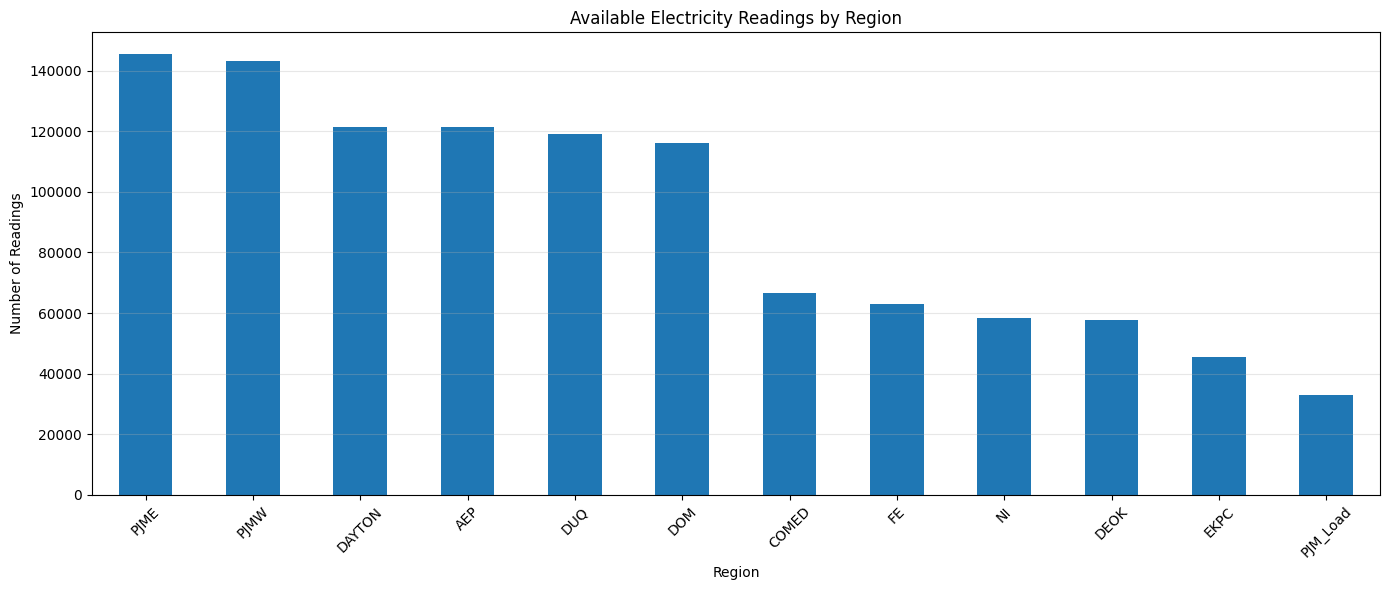

In [24]:
plt.figure(figsize=(14, 6))

long_df.groupby("Region")["Consumption"].count().sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Available Electricity Readings by Region")
plt.xlabel("Region")
plt.ylabel("Number of Readings")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 25. Evaluate Regional Data Quality
This cell builds a quality report for each region. It counts zero and negative consumption readings, measures repeated timestamps, and calculates the mean and standard deviation of consumption. These statistics help identify unusual values and differences in regional data quality.

In [25]:

# =====================================
# EDA 1: Region Quality Analysis
# =====================================

quality_report = (
    long_df.groupby("Region")
    .agg(
        Total_Readings=("Consumption", "count"),
        Zero_Readings=(
            "Consumption",
            lambda x: (x == 0).sum()
        ),
        Negative_Readings=(
            "Consumption",
            lambda x: (x < 0).sum()
        ),
        Repeated_Timestamp_Groups=(
            "Datetime",
            lambda x: x.duplicated().sum()
        ),
        Mean=("Consumption", "mean"),
        Std=("Consumption", "std")
    )
    .round(2)
)

display(quality_report)


,Total_Readings,Zero_Readings,Negative_Readings,Repeated_Timestamp_Groups,Mean,Std
Region,,,,,,
AEP,121273,0,0,4,15499.51,2591.40
COMED,66497,0,0,4,11420.15,2304.14
DAYTON,121275,0,0,4,2037.85,393.40
DEOK,57739,0,0,4,3105.10,599.86
DOM,116189,0,0,4,10949.20,2413.95
DUQ,119068,0,0,4,1658.82,301.74
EKPC,45334,0,0,4,1464.22,378.87
FE,62874,1,0,4,7792.16,1331.27
NI,58450,0,0,0,11701.68,2371.50


## 26. Explore Daily Electricity Consumption Over Time
This cell creates a separate time-series plot for each region. It resamples the observations to daily frequency using the mean consumption and plots the resulting daily trends, making long-term changes and unusual periods easier to inspect.

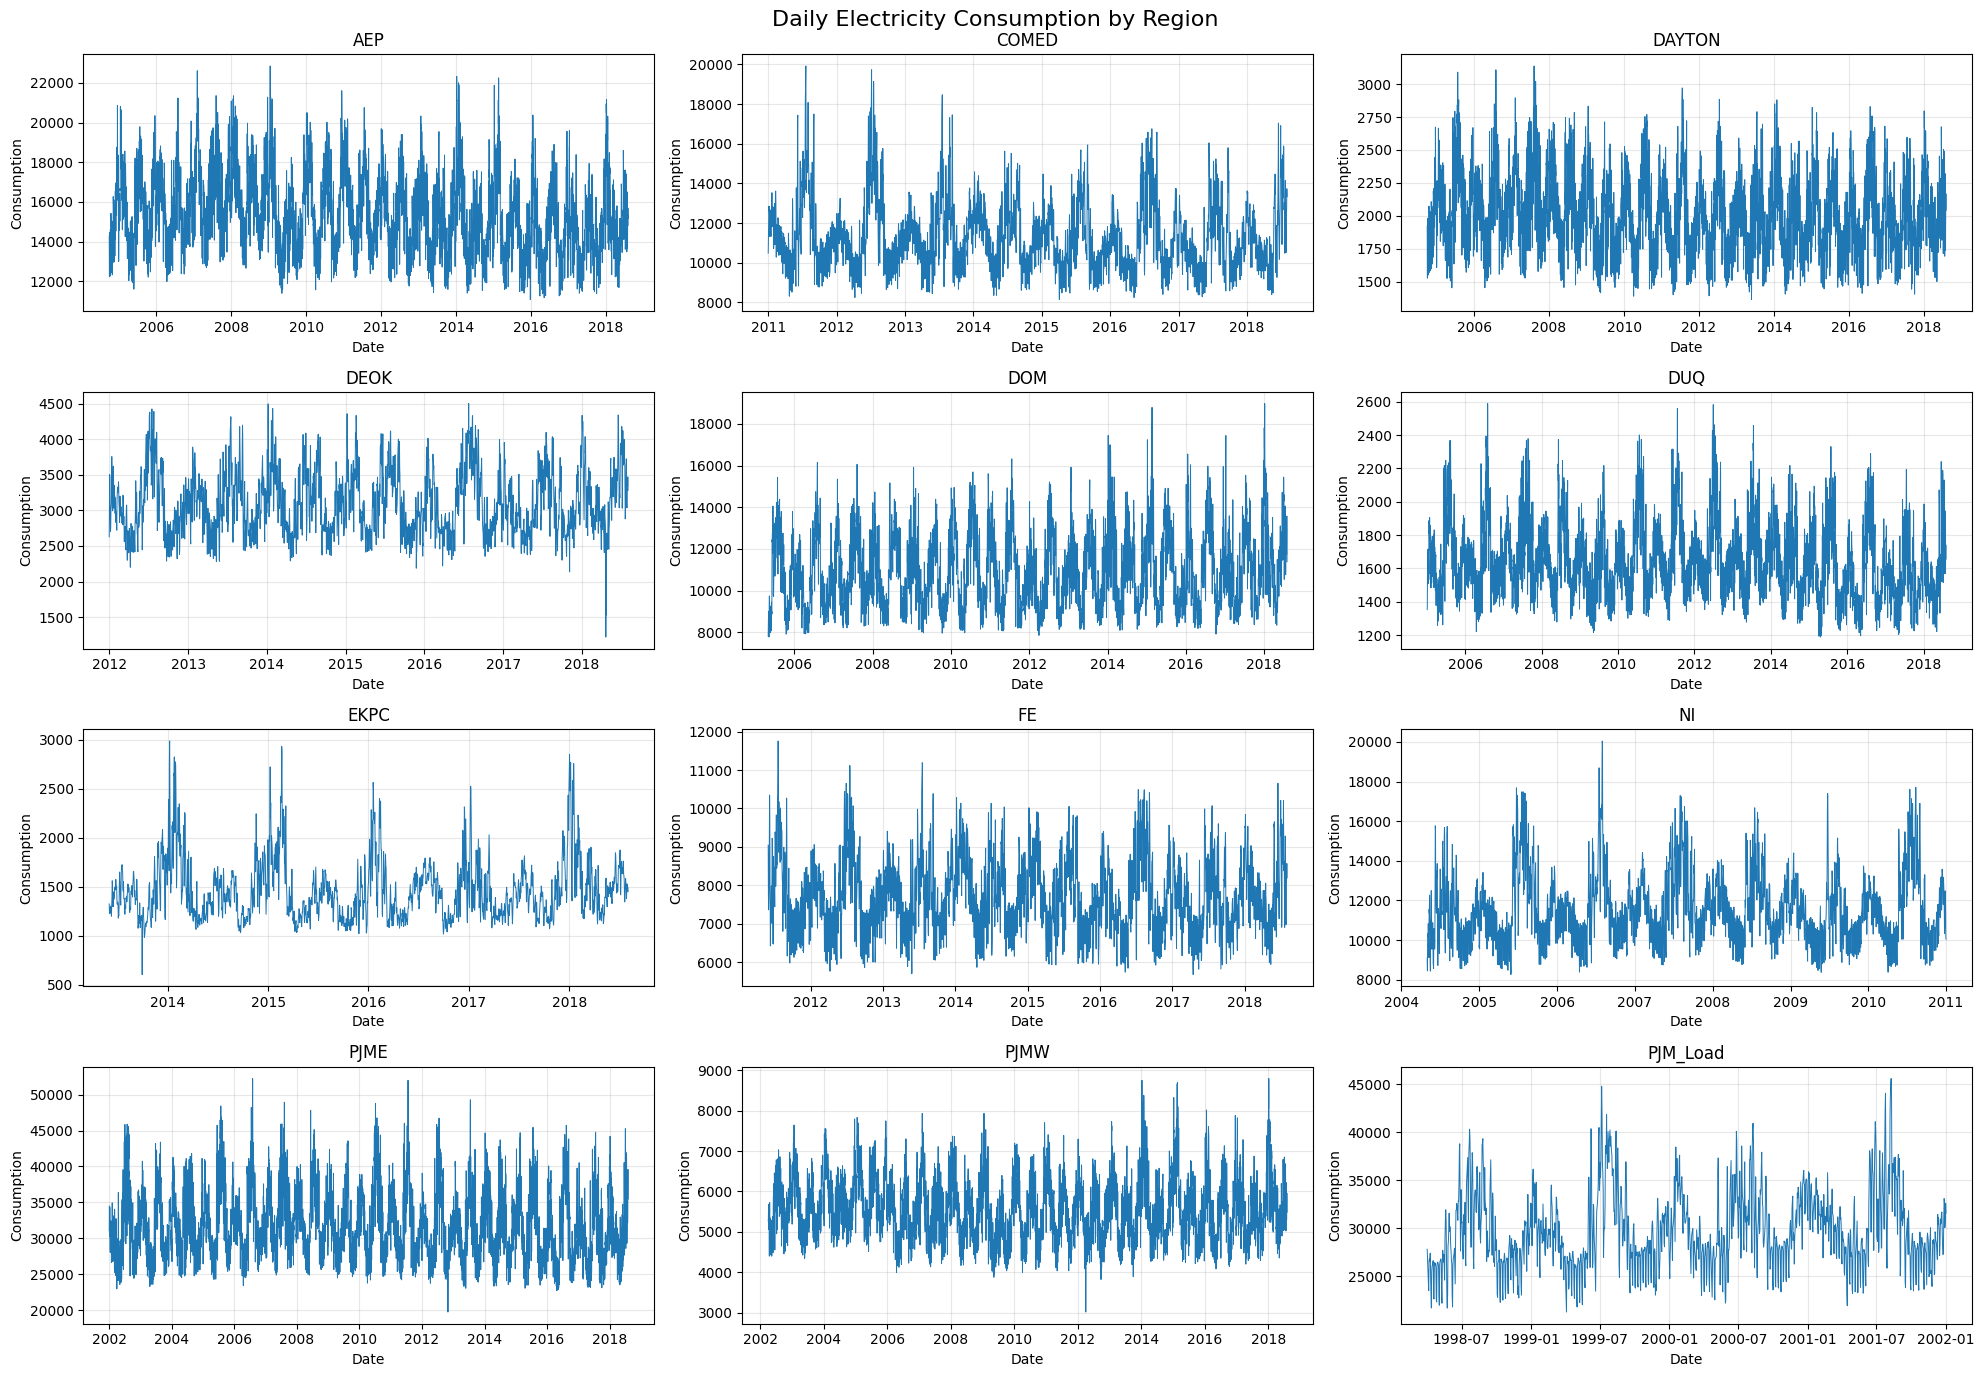

In [26]:
# =====================================
# EDA 2: Consumption Over Time
# =====================================

fig, axes = plt.subplots(
    4, 3,
    figsize=(20, 14)
)

for ax, region in zip(axes.flat, long_df["Region"].unique()):

    region_data = long_df[
        long_df["Region"] == region
    ].copy()

    daily_consumption = (
        region_data
        .set_index("Datetime")["Consumption"]
        .resample("D")
        .mean()
    )

    ax.plot(
        daily_consumption.index,
        daily_consumption.values,
        linewidth=0.7
    )

    ax.set_title(region)
    ax.set_xlabel("Date")
    ax.set_ylabel("Consumption")
    ax.grid(alpha=0.3)

plt.suptitle(
    "Daily Electricity Consumption by Region",
    fontsize=16
)

plt.tight_layout()
plt.show()


## 27. Analyze Hourly Consumption Patterns
This cell extracts the hour of the day and calculates average consumption for every region-hour combination. It then divides each hourly average by that region's overall mean and plots the normalized profiles, allowing hourly patterns to be compared across regions with different consumption scales.

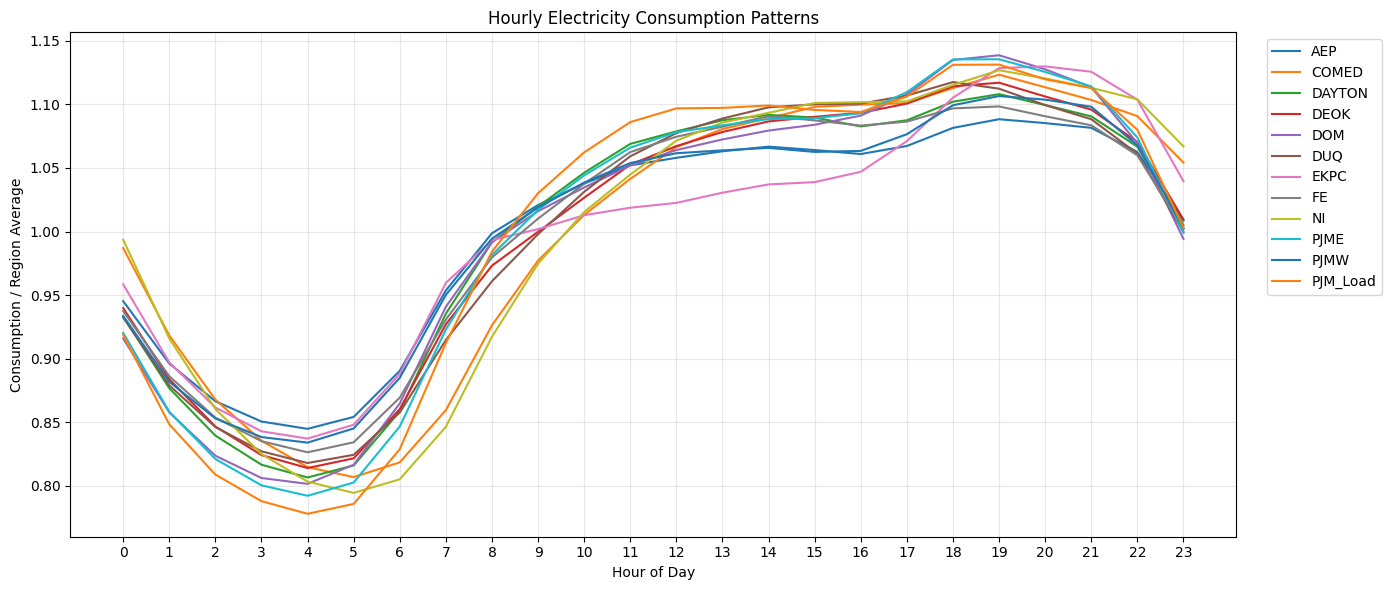

In [27]:

# =====================================
# EDA 3: Hourly Patterns
# =====================================

long_df["Hour"] = long_df["Datetime"].dt.hour

hourly_profile = (
    long_df.groupby(["Region", "Hour"])["Consumption"]
    .mean()
    .reset_index()
)

# Normalize by each region's average
region_means = (
    long_df.groupby("Region")["Consumption"]
    .mean()
    .rename("Region_Mean")
)

hourly_profile = hourly_profile.join(
    region_means,
    on="Region"
)

hourly_profile["Relative_Consumption"] = (
    hourly_profile["Consumption"]
    / hourly_profile["Region_Mean"]
)

plt.figure(figsize=(14, 6))

for region in hourly_profile["Region"].unique():

    region_data = hourly_profile[
        hourly_profile["Region"] == region
    ]

    plt.plot(
        region_data["Hour"],
        region_data["Relative_Consumption"],
        label=region
    )

plt.title("Hourly Electricity Consumption Patterns")
plt.xlabel("Hour of Day")
plt.ylabel("Consumption / Region Average")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 28. Analyze Monthly Seasonality
This cell calculates average consumption for each month and region, then normalizes the monthly averages by each region's overall mean. The line chart shows how consumption changes throughout the year while making regional patterns more comparable.

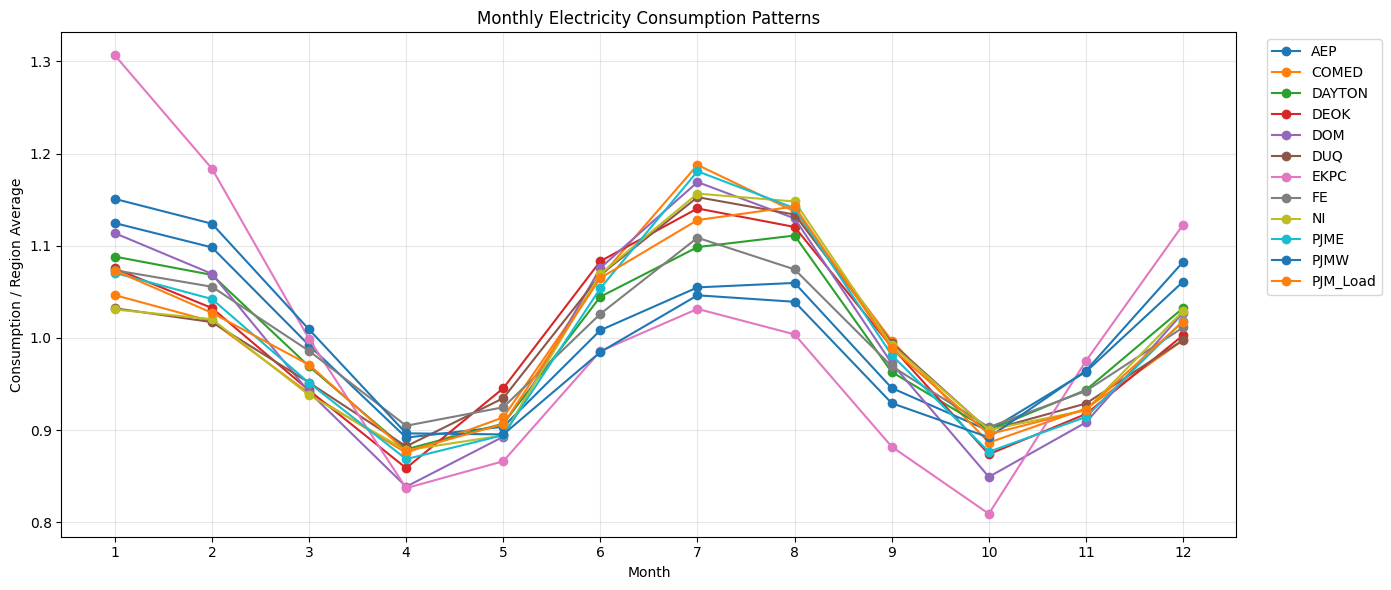

In [28]:

# =====================================
# EDA 4: Monthly Seasonality
# =====================================

long_df["Month"] = long_df["Datetime"].dt.month

monthly_profile = (
    long_df.groupby(["Region", "Month"])["Consumption"]
    .mean()
    .reset_index()
)

monthly_profile = monthly_profile.join(
    region_means,
    on="Region"
)

monthly_profile["Relative_Consumption"] = (
    monthly_profile["Consumption"]
    / monthly_profile["Region_Mean"]
)

plt.figure(figsize=(14, 6))

for region in monthly_profile["Region"].unique():

    region_data = monthly_profile[
        monthly_profile["Region"] == region
    ]

    plt.plot(
        region_data["Month"],
        region_data["Relative_Consumption"],
        marker="o",
        label=region
    )

plt.title("Monthly Electricity Consumption Patterns")
plt.xlabel("Month")
plt.ylabel("Consumption / Region Average")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 29. Analyze Weekly Consumption Patterns
This cell extracts the day of the week, calculates average consumption for each region and weekday, and normalizes the results by each region's overall average. The chart compares relative consumption patterns from Monday through Sunday.

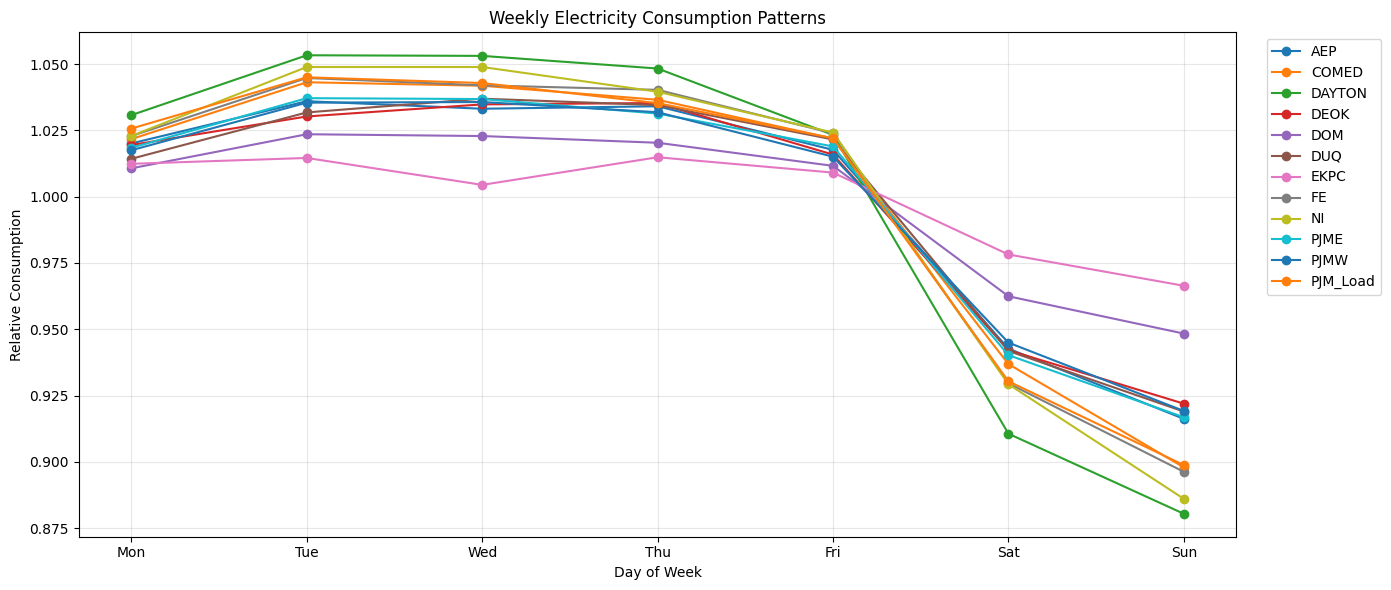

In [29]:

# Weekly Consumption Analysis

long_df["DayOfWeek"] = long_df["Datetime"].dt.dayofweek

weekly_profile = (
    long_df.groupby(["Region", "DayOfWeek"])["Consumption"]
    .mean()
    .reset_index()
)

region_avg = long_df.groupby("Region")["Consumption"].mean()

weekly_profile["Relative_Consumption"] = (
    weekly_profile["Consumption"] /
    weekly_profile["Region"].map(region_avg)
)

plt.figure(figsize=(14, 6))

for region in weekly_profile["Region"].unique():

    data = weekly_profile[
        weekly_profile["Region"] == region
    ]

    plt.plot(
        data["DayOfWeek"],
        data["Relative_Consumption"],
        marker="o",
        label=region
    )

plt.xticks(
    range(7),
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)

plt.title("Weekly Electricity Consumption Patterns")
plt.xlabel("Day of Week")
plt.ylabel("Relative Consumption")
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


## 30. Perform an Additional Monthly Consumption Analysis
This cell groups consumption by region and calendar month, calculates the monthly averages, and expresses them relative to each region's overall average. It then plots the normalized monthly profiles to compare seasonal behavior across regions.

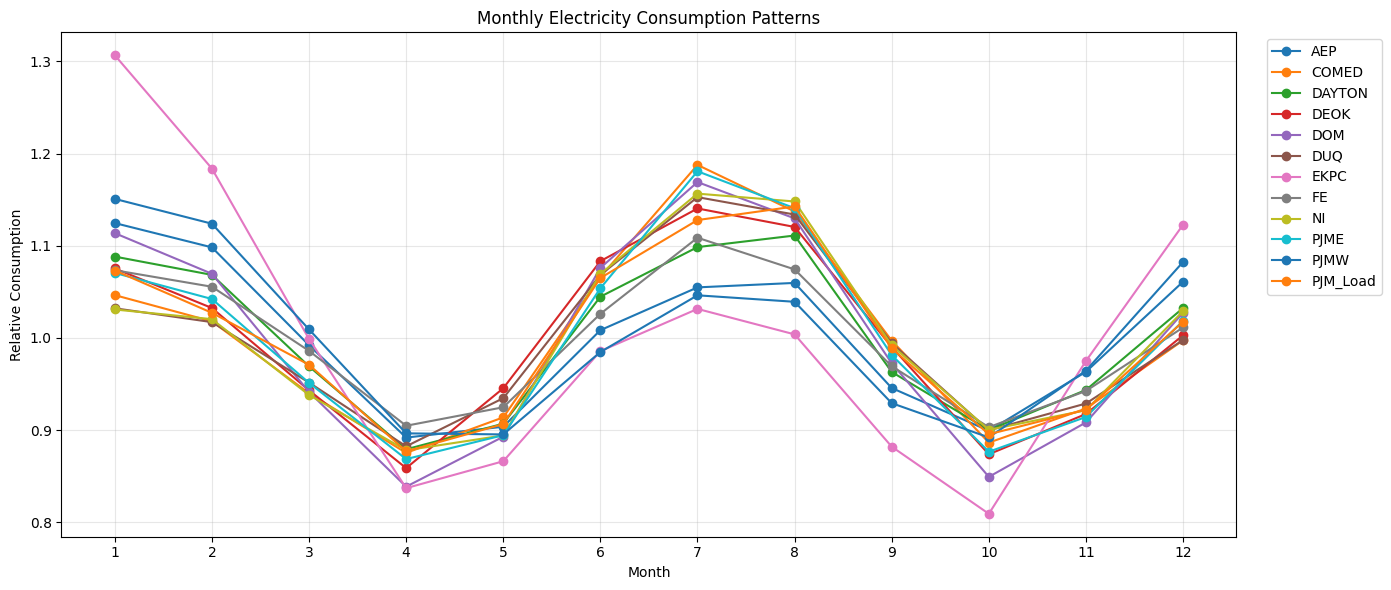

In [30]:

# Monthly Consumption Analysis

long_df["Month"] = long_df["Datetime"].dt.month

monthly_profile = (
    long_df.groupby(["Region", "Month"])["Consumption"]
    .mean()
    .reset_index()
)

monthly_profile["Relative_Consumption"] = (
    monthly_profile["Consumption"] /
    monthly_profile["Region"].map(region_avg)
)

plt.figure(figsize=(14, 6))

for region in monthly_profile["Region"].unique():

    data = monthly_profile[
        monthly_profile["Region"] == region
    ]

    plt.plot(
        data["Month"],
        data["Relative_Consumption"],
        marker="o",
        label=region
    )

plt.xticks(range(1, 13))
plt.title("Monthly Electricity Consumption Patterns")
plt.xlabel("Month")
plt.ylabel("Relative Consumption")
plt.grid(alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


## 31. Prepare the Dataset for Feature Engineering
This cell creates a working copy of the long-format data, sorts it by region and time, and removes previously added exploratory-analysis columns. This provides a consistent starting point for creating model input features.

In [31]:

# =====================================
# Feature Engineering
# =====================================

feature_df = long_df.copy()

# Sort data correctly
feature_df = feature_df.sort_values(
    ["Region", "Datetime", "Occurrence"]
).reset_index(drop=True)

# Remove previous EDA columns if present
feature_df = feature_df.drop(
    columns=["Hour", "Month", "DayOfWeek"],
    errors="ignore"
)


## 32. Create Calendar and Cyclical Time Features
This cell extracts calendar information such as hour, weekday, day, month, quarter, and day of year. It also creates a weekend indicator and applies sine/cosine transformations to hour and month so that cyclical time relationships are represented continuously.

In [32]:

# =====================================
# Time-Based Features
# =====================================

feature_df["Hour"] = feature_df["Datetime"].dt.hour

feature_df["DayOfWeek"] = (
    feature_df["Datetime"].dt.dayofweek
)

feature_df["Day"] = feature_df["Datetime"].dt.day

feature_df["Month"] = feature_df["Datetime"].dt.month

feature_df["Quarter"] = (
    feature_df["Datetime"].dt.quarter
)

feature_df["DayOfYear"] = (
    feature_df["Datetime"].dt.dayofyear
)

feature_df["IsWeekend"] = (
    feature_df["DayOfWeek"] >= 5
).astype(int)

# Cyclical Encoding

import numpy as np

feature_df["Hour_Sin"] = np.sin(
    2 * np.pi * feature_df["Hour"] / 24
)

feature_df["Hour_Cos"] = np.cos(
    2 * np.pi * feature_df["Hour"] / 24
)

feature_df["Month_Sin"] = np.sin(
    2 * np.pi * feature_df["Month"] / 12
)

feature_df["Month_Cos"] = np.cos(
    2 * np.pi * feature_df["Month"] / 12
)


## 33. Create Lag Features
This cell generates past-consumption features separately for each region. The lag columns represent the previous observation, the observation 24 rows earlier, and the observation 168 rows earlier, providing historical consumption information to the forecasting model.

In [33]:

# =====================================
# Lag Features
# =====================================

grouped = feature_df.groupby("Region")["Consumption"]

feature_df["Lag_1"] = grouped.shift(1)

feature_df["Lag_24"] = grouped.shift(24)

feature_df["Lag_168"] = grouped.shift(168)


## 34. Create Rolling Statistical Features
This cell calculates rolling mean consumption over 24 and 168 previous observations and rolling standard deviation over 24 previous observations. The values are shifted by one observation before calculation so that the current target value is not included in its own historical features.

In [34]:

# =====================================
# Rolling Features
# =====================================

feature_df["Rolling_Mean_24"] = (
    feature_df.groupby("Region")["Consumption"]
    .transform(
        lambda x: x.shift(1).rolling(24).mean()
    )
)

feature_df["Rolling_Mean_168"] = (
    feature_df.groupby("Region")["Consumption"]
    .transform(
        lambda x: x.shift(1).rolling(168).mean()
    )
)

feature_df["Rolling_Std_24"] = (
    feature_df.groupby("Region")["Consumption"]
    .transform(
        lambda x: x.shift(1).rolling(24).std()
    )
)


## 35. Remove Rows with Incomplete Model Features
This cell reports the dataset dimensions before and after dropping rows containing missing values. It then checks the remaining missing values, counts the represented regions, and displays a sample of the prepared feature dataset.

In [35]:

# =====================================
# Remove Missing Feature Rows
# =====================================

print("Before:", feature_df.shape)

feature_df = feature_df.dropna().copy()

print("After:", feature_df.shape)

print("\nMissing Values:")
print(feature_df.isnull().sum())

print("\nRegions:")
print(feature_df["Region"].nunique())

print("\nSample:")
display(feature_df.head())


Before: (1090167, 21)
After: (1088151, 21)

Missing Values:
Datetime            0
Occurrence          0
Region              0
Consumption         0
Hour                0
DayOfWeek           0
Day                 0
Month               0
Quarter             0
DayOfYear           0
IsWeekend           0
Hour_Sin            0
Hour_Cos            0
Month_Sin           0
Month_Cos           0
Lag_1               0
Lag_24              0
Lag_168             0
Rolling_Mean_24     0
Rolling_Mean_168    0
Rolling_Std_24      0
dtype: int64

Regions:
12

Sample:


,Datetime,Occurrence,Region,Consumption,Hour,DayOfWeek,Day,Month,Quarter,DayOfYear,...,Hour_Sin,Hour_Cos,Month_Sin,Month_Cos,Lag_1,Lag_24,Lag_168,Rolling_Mean_24,Rolling_Mean_168,Rolling_Std_24
168,2004-10-08 01:00:00,1,AEP,12468.0,1,4,8,10,4,282,...,0.258819,0.965926,-0.866025,0.5,13271.0,12484.0,12379.0,14450.333333,13870.315476,1475.548466
169,2004-10-08 02:00:00,1,AEP,12046.0,2,4,8,10,4,282,...,0.500000,0.866025,-0.866025,0.5,12468.0,12054.0,11935.0,14449.666667,13870.845238,1476.478821
170,2004-10-08 03:00:00,1,AEP,11749.0,3,4,8,10,4,282,...,0.707107,0.707107,-0.866025,0.5,12046.0,11745.0,11692.0,14449.333333,13871.505952,1477.043983
171,2004-10-08 04:00:00,1,AEP,11784.0,4,4,8,10,4,282,...,0.866025,0.500000,-0.866025,0.5,11749.0,11757.0,11597.0,14449.500000,13871.845238,1476.725755
172,2004-10-08 05:00:00,1,AEP,11919.0,5,4,8,10,4,282,...,0.965926,0.258819,-0.866025,0.5,11784.0,12041.0,11681.0,14450.625000,13872.958333,1474.594117


## 36. Define the Model Features and Target
This cell specifies `Consumption` as the prediction target and selects the regional, calendar, cyclical, lag, and rolling-statistic columns as input features. It then creates the feature matrix `X` and target vector `y` and displays their dimensions.

In [36]:

# =====================================
# Define Features and Target
# =====================================

target = "Consumption"

features = [
    "Region",
    "Occurrence",

    "Hour",
    "DayOfWeek",
    "Day",
    "Month",
    "Quarter",
    "DayOfYear",
    "IsWeekend",

    "Hour_Sin",
    "Hour_Cos",
    "Month_Sin",
    "Month_Cos",

    "Lag_1",
    "Lag_24",
    "Lag_168",

    "Rolling_Mean_24",
    "Rolling_Mean_168",
    "Rolling_Std_24"
]

X = feature_df[features]

y = feature_df[target]

print("X Shape:", X.shape)
print("y Shape:", y.shape)


X Shape: (1088151, 19)
y Shape: (1088151,)


## 37. Split the Data Chronologically into Training and Testing Sets
This cell splits each region's observations in chronological order, using the first 80% for training and the final 20% for testing. It combines the regional partitions, creates the training and testing feature matrices and targets, and displays their sizes and date ranges.

In [37]:

# =====================================
# Chronological Train Test Split
# =====================================

train_parts = []
test_parts = []

for region, data in feature_df.groupby("Region"):

    data = data.sort_values(
        ["Datetime", "Occurrence"]
    )

    split_idx = int(len(data) * 0.8)

    train_parts.append(data.iloc[:split_idx])

    test_parts.append(data.iloc[split_idx:])

train_df = pd.concat(train_parts)

test_df = pd.concat(test_parts)

X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("Training Shape:", X_train.shape)

print("Testing Shape:", X_test.shape)

print("\nTrain Date Range:")
print(train_df["Datetime"].min(), "to",
      train_df["Datetime"].max())

print("\nTest Date Range:")
print(test_df["Datetime"].min(), "to",
      test_df["Datetime"].max())


Training Shape: (870515, 19)
Testing Shape: (217636, 19)

Train Date Range:
1998-04-08 02:00:00 to 2017-07-22 14:00:00

Test Date Range:
2001-04-03 06:00:00 to 2018-08-03 00:00:00


## 38. Train the First Random Forest Regression Model
This cell builds a preprocessing and modeling pipeline. It one-hot encodes the categorical region feature, passes numeric features through unchanged, and trains a Random Forest regressor on the training data. The pipeline keeps preprocessing and prediction steps together for consistent use during evaluation.

In [38]:

# =====================================
# First ML Model
# =====================================

categorical_features = ["Region"]

numeric_features = [
    col for col in features
    if col not in categorical_features
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "region_encoder",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=20,
                min_samples_leaf=2,
                n_jobs=-1,
                random_state=42
            )
        )
    ]
)

model.fit(X_train, y_train)

print("Model Training Completed!")


Model Training Completed!


## 39. Evaluate the First Model
This cell generates predictions for the test set and calculates four regression metrics: Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R-squared. These metrics describe prediction error and the model's ability to explain variation in electricity consumption.

In [39]:

# =====================================
# Model Evaluation
# =====================================


predictions = model.predict(X_test)

mae = mean_absolute_error(
    y_test,
    predictions
)

mse = mean_squared_error(
    y_test,
    predictions
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test,
    predictions
)

print("MAE:", round(mae, 2))

print("MSE:", round(mse, 2))

print("RMSE:", round(rmse, 2))

print("R2 Score:", round(r2, 4))


MAE: 105.76
MSE: 37417.03
RMSE: 193.43
R2 Score: 0.9996


## 40. Train and Compare Multiple Regression Models
This cell defines a baseline Dummy Regressor, Random Forest, Extra Trees, and HistGradientBoosting models. It trains each model using the selected preprocessing pipeline, stores test predictions, calculates MAE, RMSE, and R-squared, and collects the results in a comparison table.

In [40]:
# Models
models = {
    "Dummy": DummyRegressor(strategy="mean"),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ),

    "Hist Gradient Boosting": Pipeline([
        ("preprocessor", ColumnTransformer([
            (
                "region",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ),
                ["Region"]
            ),
            (
                "numeric",
                "passthrough",
                numeric_features
            )
        ])),
        (
            "regressor",
            HistGradientBoostingRegressor(
                max_iter=100,
                max_leaf_nodes=31,
                random_state=42
            )
        )
    ])
}

# Results
results = []
predictions_dict = {}
trained_models = {}

for name, regressor in models.items():

    if name == "Hist Gradient Boosting":
        current_model = regressor
    else:
        current_model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", regressor)
        ])

    print(f"Training {name}...")

    current_model.fit(X_train, y_train)
    trained_models[name] = current_model

    predictions = current_model.predict(X_test)

    predictions_dict[name] = predictions

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values("RMSE"))


Training Dummy...
Training Random Forest...
Training Extra Trees...
Training Hist Gradient Boosting...


,Model,MAE,RMSE,R2
2,Extra Trees,104.517473,187.250861,0.999668
1,Random Forest,105.762546,193.434829,0.999646
3,Hist Gradient Boosting,154.274541,271.921059,0.999300
0,Dummy,7890.085452,10279.349361,-0.000777


In [41]:
# Define the models directory
save_path = r"D:\next Gen In Ai\Final Project"

# Create directory if it does not exist
os.makedirs(save_path, exist_ok=True)

# Save all trained models
joblib.dump(
    trained_models,
    os.path.join(save_path, "electricity_grid_all_models.pkl")
)

# Identify the best model based on RMSE
best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(),
    "Model"
]

best_model = trained_models[best_model_name]

# Save the best model
joblib.dump(
    best_model,
    os.path.join(save_path, "best_electricity_model.pkl")
)

# Save the best model name
joblib.dump(
    best_model_name,
    os.path.join(save_path, "best_model_name.pkl")
)

print("All models saved successfully!")
print("Best Model:", best_model_name)
print("Saved Location:", save_path)

All models saved successfully!
Best Model: Extra Trees
Saved Location: D:\next Gen In Ai\Final Project


In [42]:
PROJECT_PATH = r"D:\next Gen In Ai\Final Project"
MODELS_PATH = os.path.join(PROJECT_PATH, "Models")

# Load the best model
best_model = trained_models[best_model_name]

# Create model bundle
model_bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "features": features,
    "metrics": results_df.to_dict(orient="records"),
    "history": feature_df[
        ["Datetime", "Region", "Occurrence", "Consumption"]
    ].copy()
}

# Save model bundle
joblib.dump(
    model_bundle,
    os.path.join(MODELS_PATH, "electricity_grid_model.pkl")
)

print("Model bundle saved successfully!")

FileNotFoundError: [Errno 2] No such file or directory: 'D:\\next Gen In Ai\\Final Project\\Models\\electricity_grid_model.pkl'

## 41. Visualize the Model Comparison
This cell creates three bar charts to compare the models using MAE, RMSE, and R-squared. It adds metric labels and values to the bars so that prediction errors and goodness of fit can be compared visually.

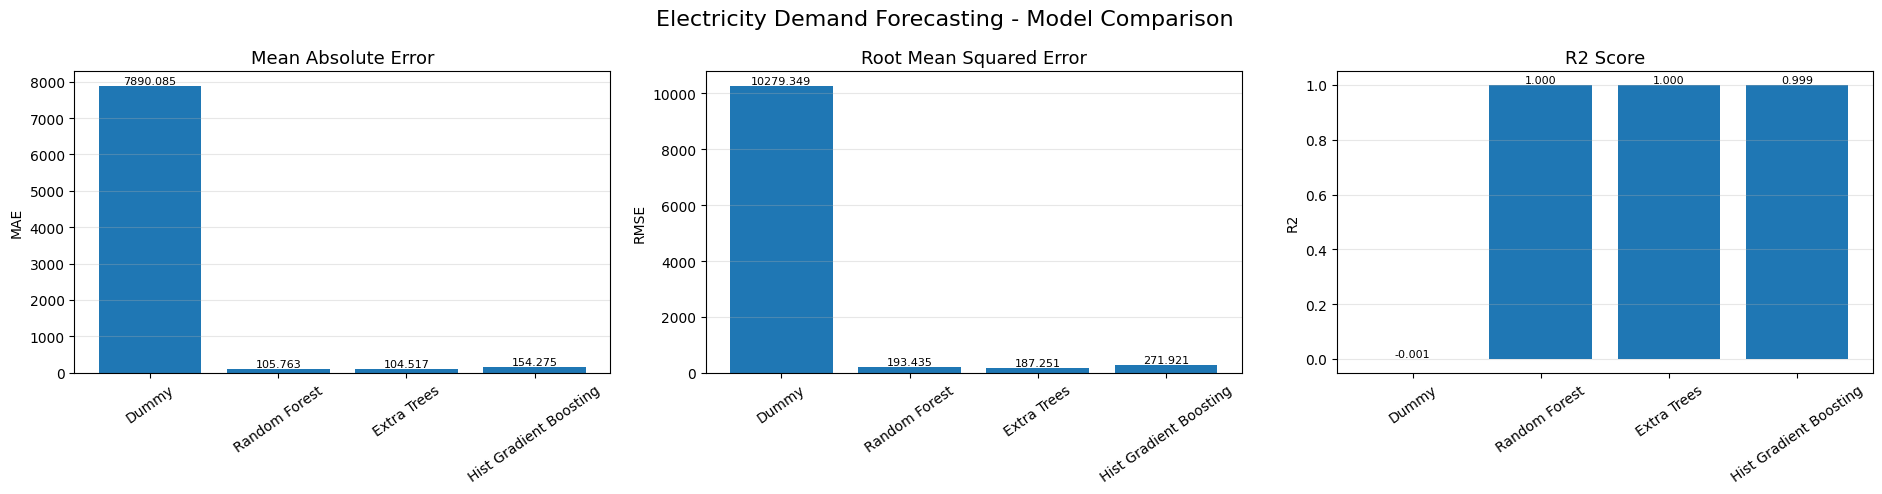

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

metrics = [
    ("MAE", "Mean Absolute Error"),
    ("RMSE", "Root Mean Squared Error"),
    ("R2", "R2 Score")
]

for ax, (metric, title) in zip(axes, metrics):

    bars = ax.bar(
        results_df["Model"],
        results_df[metric]
    )

    ax.set_title(title, fontsize=13)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)

    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

plt.suptitle(
    "Electricity Demand Forecasting - Model Comparison",
    fontsize=16
)

plt.tight_layout()
plt.show()
